In [1]:
import pandas as pd
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from xgboost import XGBClassifier
from matplotlib import pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate, validation_curve
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, precision_score, f1_score, recall_score, confusion_matrix

In [2]:
df = pd.read_csv("../data/raw/1200_song_mapped.csv",",")
df.head()

/Library/Frameworks/Python.framework/Versions/3.7/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3553: FutureWarning: In a future version of pandas all arguments of read_csv except for the argument 'filepath_or_buffer' will be keyword-only
  exec(code_obj, self.user_global_ns, self.user_ns)


,Unnamed: 0,track,artist,duration (ms),popularity,uri,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time signature,labels
0,0,1999,Prince,379266,68,spotify:track:2H7PHVdQ3mXqEHXcvclTB0,0.866,0.730,5,-8.201,0.0767,0.13700,0.000000,0.0843,0.625,118.523,4,1
1,1,23,Blonde Redhead,318800,43,spotify:track:4HIwL9ii9CcXpTOTzMq0MP,0.381,0.832,8,-5.069,0.0492,0.01890,0.196000,0.1530,0.166,120.255,4,0
2,2,9 Crimes,Damien Rice,217946,60,spotify:track:5GZEeowhvSieFDiR8fQ2im,0.346,0.139,0,-15.326,0.0321,0.91300,0.000077,0.0934,0.116,136.168,4,0
3,3,99 Luftballons,Nena,233000,2,spotify:track:6HA97v4wEGQ5TUClRM0XLc,0.466,0.438,4,-12.858,0.0608,0.08900,0.000006,0.1130,0.587,193.100,4,1
4,4,A Boy Brushed Red Living In Black And White,Underoath,268000,60,spotify:track:47IWLfIKOKhFnz1FUEUIkE,0.419,0.932,1,-3.604,0.1060,0.00171,0.000000,0.1370,0.445,169.881,4,2


In [4]:
# Mapping emotions
emotions_mapping = {0: 'sad', 1: 'happy', 2:'energetic', 3:'calm'}

In [3]:
# Column renaming
df.columns = [x.replace(' ', '_').replace('(', '').replace(')', '') for x in df.columns]
print(df.columns)

Index(['Unnamed:_0', 'track', 'artist', 'duration_ms', 'popularity', 'uri',
       'danceability', 'energy', 'key', 'loudness', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'time_signature', 'labels'],
      dtype='object')


In [5]:
df_new = df[['track', 'artist', 'popularity', 'duration_ms',
       'danceability', 'acousticness', 'energy', 'instrumentalness',
       'liveness', 'valence', 'loudness', 'speechiness', 'tempo', 'labels']]
df = df_new.rename({'track' : 'name','duration_ms':'length','labels':'mood'}, axis=1)
df.head()

,name,artist,popularity,length,danceability,acousticness,energy,instrumentalness,liveness,valence,loudness,speechiness,tempo,mood
0,1999,Prince,68,379266,0.866,0.13700,0.730,0.000000,0.0843,0.625,-8.201,0.0767,118.523,1
1,23,Blonde Redhead,43,318800,0.381,0.01890,0.832,0.196000,0.1530,0.166,-5.069,0.0492,120.255,0
2,9 Crimes,Damien Rice,60,217946,0.346,0.91300,0.139,0.000077,0.0934,0.116,-15.326,0.0321,136.168,0
3,99 Luftballons,Nena,2,233000,0.466,0.08900,0.438,0.000006,0.1130,0.587,-12.858,0.0608,193.100,1
4,A Boy Brushed Red Living In Black And White,Underoath,60,268000,0.419,0.00171,0.932,0.000000,0.1370,0.445,-3.604,0.1060,169.881,2


In [6]:
# Data validation
df['mood'].value_counts()

1    300
0    300
2    300
3    300
Name: mood, dtype: int64

In [ ]:
# Check for null values
df.isnull().sum()

## **Data Prep / Feature Engineering**

In [7]:
# Define X and y datasets
X = df.loc[:, 'danceability':'tempo']
y = df['mood']

In [ ]:
X.head()

In [8]:
## Use Robust Scaler to scale all features
rb = RobustScaler()
X = rb.fit_transform(X)
X

array([[ 1.42946708e+00, -8.35459362e-02,  2.23938224e-01, ...,
        -2.47991271e-04,  1.27715356e+00, -5.11459374e-02],
       [-5.97701149e-01, -2.15985870e-01,  3.81467181e-01, ...,
         3.10435473e-01,  2.47191011e-01,  5.06985968e-04],
       [-7.43991641e-01,  7.86677507e-01, -6.88803089e-01, ...,
        -7.07023113e-01, -3.93258427e-01,  4.75075675e-01],
       ...,
       [ 1.44618600e+00, -9.47601559e-02, -8.18532819e-02, ...,
         1.08868168e-01,  1.96629213e+00,  5.21300866e-02],
       [ 3.76175549e-02, -2.34455690e-01,  2.02316602e-01, ...,
        -1.50729094e-01,  5.50561798e-01, -5.36808672e-03],
       [ 6.93834901e-01, -2.20920127e-01,  4.04633205e-01, ...,
         3.60430513e-01, -1.94756554e-01,  1.12640353e-01]])

In [ ]:
## Export Scaler
with open('rb_scaler.pkl', 'wb') as file:
    pickle.dump(rb, file)

### OPTIONAL Remove collinear features (if wanted)

In [ ]:
# Calculate the correlation matrix
correlation_matrix = X.corr()

# Visualize the correlation matrix using a heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")

In [ ]:
# Remove highly correlated features
threshold = 0.8  # Adjust the threshold based on your preference
high_corr_features = set()
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > threshold:
            colname = correlation_matrix.columns[i]
            high_corr_features.add(colname)

X_filtered = X.drop(high_corr_features, axis=1)

In [ ]:
# Manual feature selection
X_filtered = X[['danceability','energy','instrumentalness','liveness','valence','speechiness','tempo']]
X_filtered

# Model Evaluation

## Determine model to use

In [12]:
# Splitting training data and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

## Basic train/test split
def base_models_v2():
    print("Base Models....")
    classifiers = [('LR', LogisticRegression()),
                   ('KNN', KNeighborsClassifier()),
                   ("SVC", SVC()),
                   ("CART", DecisionTreeClassifier()),
                   ("RF", RandomForestClassifier()),
                   ('GBM', GradientBoostingClassifier()),
                   ('XGBoost', XGBClassifier(use_label_encoder=False, eval_metric='logloss')),
                   ]
    
    # Regular model evaluation (without PCA)
    for name, model in classifiers:
        model.fit(X_train, y_train)

        predictions = model.predict(X_test)
        accuracy = accuracy_score(predictions, y_test)

        print('{}:\nAccuracy: {:3.3f}\nF1 Score (Macro): {:3.3f}\n'.format(name,accuracy_score(predictions, y_test),
                                                                                f1_score(predictions, y_test,average='macro')))
    return classifiers

classifiers = base_models_v2()

Base Models....
LR:
Accuracy: 0.803
F1 Score (Macro): 0.803

KNN:
Accuracy: 0.706
F1 Score (Macro): 0.709

SVC:
Accuracy: 0.778
F1 Score (Macro): 0.780

CART:
Accuracy: 0.739
F1 Score (Macro): 0.740

RF:
Accuracy: 0.822
F1 Score (Macro): 0.824

GBM:
Accuracy: 0.789
F1 Score (Macro): 0.789

XGBoost:
Accuracy: 0.775
F1 Score (Macro): 0.775



## Final model selection / evaluation

In [13]:
# Choosing Random Forest
final_model = classifiers[4][1]
final_model

RandomForestClassifier()

In [14]:
# Get predictions on test set
y_pred = final_model.predict(X_test)

In [15]:
print('Accuracy: {:3.3f}\nF1 Score (Macro): {:3.3f}\n'.format(accuracy_score(y_pred, y_test),
                                                              f1_score(y_pred, y_test,average='macro')))
print("Classification Report:\n", classification_report(y_test, y_pred,target_names=[emotions_mapping[0],emotions_mapping[1],emotions_mapping[2],emotions_mapping[3]]))

Accuracy: 0.822
F1 Score (Macro): 0.824

Classification Report:
               precision    recall  f1-score   support

         sad       0.88      0.84      0.86        90
       happy       0.67      0.78      0.72        90
   energetic       0.78      0.71      0.74        90
        calm       0.98      0.96      0.97        90

    accuracy                           0.82       360
   macro avg       0.83      0.82      0.82       360
weighted avg       0.83      0.82      0.82       360



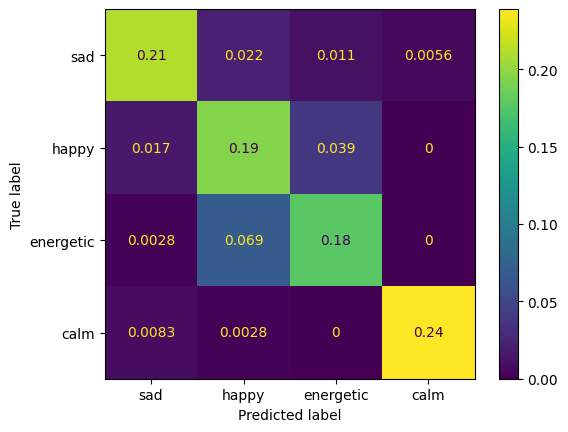

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, normalize='all')
cmd = ConfusionMatrixDisplay(cm, display_labels=[emotions_mapping[0],emotions_mapping[1],emotions_mapping[2],emotions_mapping[3]])
cmd.plot()

Text(0.5, 1.0, 'Global Feature Importance - Built-in Method')

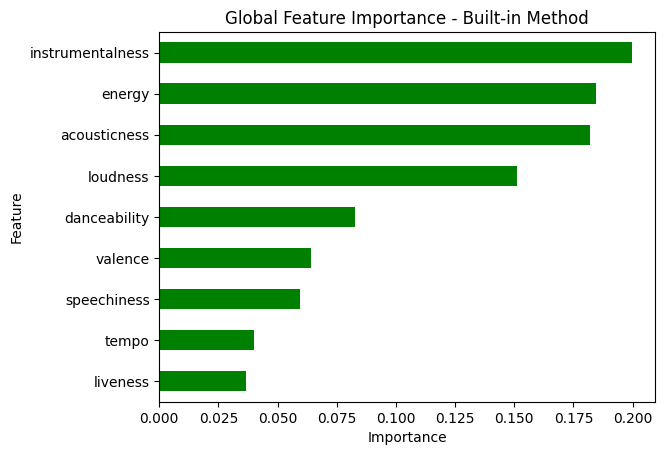

In [17]:
global_importances = pd.Series(final_model.feature_importances_, index=df.loc[:, 'danceability':'tempo'].columns)
global_importances.sort_values(ascending=True, inplace=True)
global_importances.plot.barh(color='green')
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Global Feature Importance - Built-in Method")

In [18]:
final_model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'auto',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

### Save model to pickle file

In [19]:
import pickle

filename = "music_to_mood_model.pickle"

# save model
pickle.dump(final_model, open(filename, "wb"))

# load model
#loaded_model = pickle.load(open(filename, "rb"))

In [20]:
# load model
loaded_model = pickle.load(open(filename, "rb"))

## Apply model to survey data

In [ ]:
survey_spotify_data = pd.read_csv('../data/raw/full_survey_w_all_spotify_data.csv',',')
survey_spotify_data.head()

In [ ]:
# Drop certain rows
survey_spotify_data = survey_spotify_data.drop(['Unnamed: 0', 'index','Timestamp'],axis=1)

In [ ]:
# Get condensed row
columns_to_choose = ['Response_Id', 'Current_Mood','danceability','energy', 'loudness', 'speechiness', 'acousticness','instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
survey_data_condensed = survey_spotify_data.loc[:,columns_to_choose].rename({'duration_ms':'length'},axis=1)
survey_data_condensed.head()

In [ ]:
# Get specific rows for model inference
X_survey = survey_data_condensed[['danceability','acousticness','energy','instrumentalness','liveness','valence','loudness','speechiness','tempo']]

In [ ]:
# Transform data using robust scaler
X_survey_transformed = rb.transform(X_survey)
X_survey_transformed

In [ ]:
# Get predictions on survey data
survey_preds = final_model.predict(X_survey_transformed)
survey_preds

In [ ]:
# Get predicted mood probabilities on survey data
survey_probs = final_model.predict_proba(X_survey_transformed)
survey_probs

In [ ]:
# Concatenate mood predictions to main dataframe
survey_data_condensed['mood'] = survey_preds
survey_data_condensed['mood'] = survey_data_condensed['mood'].map(emotions_mapping)
survey_data_condensed

In [ ]:
# Concatenate mood PROBABILITY predictions to main dataframe
survey_data_condensed[['sad','happy','energetic','calm']] = final_model.predict_proba(X_survey_transformed)
survey_data_condensed

In [ ]:
# Merge predictions back to main dataframe
final_data = survey_spotify_data.merge(survey_data_condensed,on=['Response_Id', 'Current_Mood', 'danceability', 'energy', 'loudness',
                                                             'speechiness', 'acousticness', 'instrumentalness', 'liveness','valence', 'tempo'],how='left')
final_data

In [ ]:
# Save data to interim data folder
final_data.to_csv('../data/interim/survey_data_spotify_with_mood.csv',',')